# Lab: Finding the Optimal Price

**Goal:** write code that searches for the price that maximizes revenue, and keep a running count of how many customers you experimented on.

- The best price is somewhere between 0 and 70.
- There are several local peaks, but only one global best.
- At the true optimum, each customer brings in about **$11.925** of expected revenue. Use this to report what share of the best possible revenue you captured.

## Setup: the `sales` simulator

**What it does:** imports the libraries, creates a random number generator `rng`, and defines two functions:
- `purchase_probability(price)` is the *true* chance that a customer buys at a given price. It's hidden from you in real life, so **don't use it to search for the price.** Only use it to check your answer at the end.
- `sales(price, rng, mean_customers)` runs one experiment. It sends you about `mean_customers` customers and returns an array of 0s and 1s (1 = bought).

**How to use it:** `price * sales(price, rng=rng, mean_customers=300)` gives the revenue from each customer. `.mean()` of that array is revenue per customer, and `len()` of it is how many customers you used. Add those lengths together to track your total customers.

**Connects to next:** every experiment below goes through `sales()`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# My Price Search

The search has three stages, and each one narrows things down:

1. **Coarse grid:** test prices 0, 2.5, 5, …, 70 with a few customers each to find roughly where the revenue peaks are.
2. **Refine:** zoom in around the top 3 peaks. Test a fine grid of nearby prices, fit a curve (a quadratic), and take its highest point. Do this twice, with a narrower window and more customers the second time.
3. **Head-to-head:** the two best peaks can be close in revenue, so compare them directly with a two-sample Z-test. Add customers in batches until one is clearly better, or until a limit is reached.

Every experiment goes through `run_price`, which writes it to a `ledger`. That's how we count every customer and every dollar of revenue.

`purchase_probability` (the true curve) is **only** used at the very end to check the result. The search uses `sales()` alone.

## A. Helpers: run an experiment and record it

- `run_price(price, n, stage)` runs one experiment at `price` with about `n` customers. It returns revenue per customer (one number per customer) and adds a row to `ledger`.
- `summarize(price, revenue)` returns mean revenue per customer, its standard error, and the number of customers.
- `search_rng` is the random generator for the whole search. Change the seed to rerun with different customers.

In [2]:
search_rng = np.random.default_rng(2026)
ledger = [] # One row per experiment: stage, price, customers, revenue

def run_price(price, n, stage):
    price = float(price)
    revenue = price * sales(price, mean_customers=n, rng=search_rng) # Revenue from each customer
    ledger.append({"stage": stage, "price": price,
                   "customers": len(revenue), "revenue": revenue.sum()})
    return revenue

def summarize(price, revenue):
    return {"price": price,
            "mean": revenue.mean(),
            "se": revenue.std(ddof=1) / np.sqrt(len(revenue)),
            "customers": len(revenue)}

## B. Stage 1: coarse grid search

**What it does:** tests every price from 0 to 70 in steps of 2.5, with about 200 customers each. Then it finds the **local peaks**: prices that earn more than both neighbors. It keeps the top 3, each at least $5 apart so they come from different hills.

**Why:** the revenue curve has more than one hill. Local search from a single starting point could climb the wrong one, so we first look at the whole range cheaply.

**Connects to next:** `candidates` are the starting points for Stage 2.

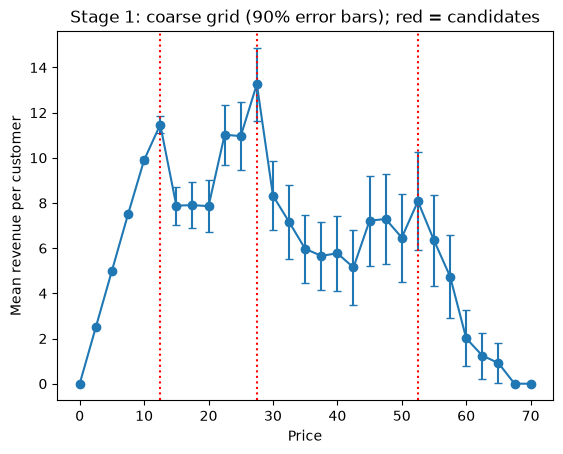

Candidate prices: [27.5, 12.5, 52.5]


In [3]:
grid = np.arange(0, 70.01, 2.5)
coarse = pd.DataFrame([summarize(p, run_price(p, 200, "1 coarse grid")) for p in grid])

# Local peaks: revenue at least as high as both neighbors
m = coarse["mean"].to_numpy()
is_peak = np.r_[m[0] > m[1], (m[1:-1] >= m[:-2]) & (m[1:-1] >= m[2:]), m[-1] > m[-2]]

# Keep the top 3 peaks, at least $5 apart
candidates = []
for p in coarse[is_peak].sort_values("mean", ascending=False)["price"]:
    if all(abs(p - q) > 5 for q in candidates):
        candidates.append(p)
candidates = candidates[:3]

plt.errorbar(coarse["price"], coarse["mean"], yerr=1.645 * coarse["se"], fmt="o-", capsize=3)
for p in candidates:
    plt.axvline(p, color="red", linestyle=":")
plt.xlabel("Price"); plt.ylabel("Mean revenue per customer")
plt.title("Stage 1: coarse grid (90% error bars); red = candidates")
plt.show()

print("Candidate prices:", candidates)

## C. Stage 2: refine each candidate

**What it does:** for each candidate price:
1. tests prices within ±2.5 of it, every 0.5, with about 400 customers each, and fits a quadratic (a hill-shaped curve) to revenue vs. price. The top of the curve is the new estimate.
2. zooms in again: ±1.5 around that estimate with about 800 customers each, then fits again.

The fit uses all nearby prices at once, so it averages out much of the noise. Picking the single best observed price would be much noisier.

**Connects to next:** `refined` lists each hill's best price and its estimated revenue. The top two go to Stage 3.

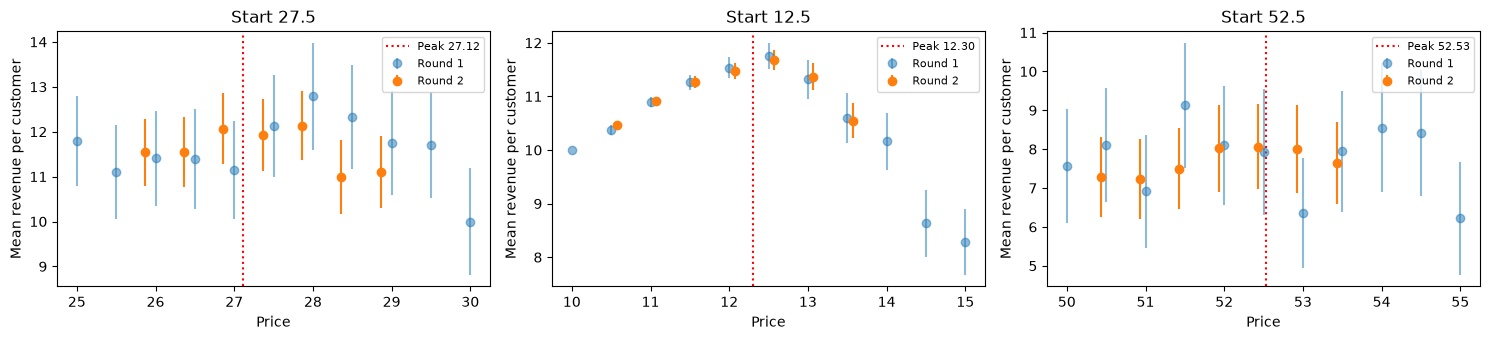

,start,round_1_peak,best_price,estimated_revenue
0,27.5,27.361,27.117,11.982
1,12.5,12.069,12.296,11.477
2,52.5,51.930,52.525,7.926


In [4]:
def zoom(center, half_width, n):
    prices = np.unique(np.clip(np.arange(center - half_width, center + half_width + 0.01, 0.5), 0, 70))
    df = pd.DataFrame([summarize(p, run_price(p, n, "2 refine")) for p in prices])
    a, b, c = np.polyfit(df["price"], df["mean"], 2, w=1 / df["se"].clip(lower=1e-6)) # Weighted quadratic fit
    if a < 0: # Hill shape: use the top of the curve (kept inside the window)
        peak = float(np.clip(-b / (2 * a), prices.min(), prices.max()))
    else:     # No hill shape: fall back to the best observed price
        peak = float(df.loc[df["mean"].idxmax(), "price"])
    return peak, a * peak**2 + b * peak + c, df

refined = []
fig, axes = plt.subplots(1, len(candidates), figsize=(5 * len(candidates), 3.5))
for ax, start in zip(np.atleast_1d(axes), candidates):
    peak_1, _, df_1 = zoom(start, 2.5, 400)
    peak_2, rev_2, df_2 = zoom(peak_1, 1.5, 800)
    refined.append({"start": start, "round_1_peak": peak_1,
                    "best_price": peak_2, "estimated_revenue": rev_2})
    ax.errorbar(df_1["price"], df_1["mean"], yerr=1.645 * df_1["se"], fmt="o", alpha=0.5, label="Round 1")
    ax.errorbar(df_2["price"], df_2["mean"], yerr=1.645 * df_2["se"], fmt="o", label="Round 2")
    ax.axvline(peak_2, color="red", linestyle=":", label=f"Peak {peak_2:.2f}")
    ax.set(title=f"Start {start:g}", xlabel="Price", ylabel="Mean revenue per customer")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

refined = pd.DataFrame(refined).sort_values("estimated_revenue", ascending=False)
refined.round(3)

## D. Stage 3: head-to-head between the top two peaks

**What it does:** runs the two best prices side by side, in batches of about 500 customers per price. After each batch it computes the difference in mean revenue per customer and a **95%** confidence interval using the two-sample Z-test: the difference in means, plus or minus 1.96 × √(s_A²/n_A + s_B²/n_B).
- It stops when the interval no longer includes 0, which means one price is clearly better, but only after at least 4 batches.
- If it never becomes clear (40 batches), it picks the price with the higher mean. The two are nearly equal in that case, so either choice costs little.

**Why 95% here, not 90%:** we check after every batch. Checking many times makes a false "winner" more likely, so a stricter level offsets that. This step is also cheap, because both prices are already near the top and customers pay well.

**Connects to next:** `best_price` is the final answer.

In [5]:
p_A, p_B = refined["best_price"].iloc[0], refined["best_price"].iloc[1]
rev_A, rev_B = np.array([]), np.array([])
h2h = []
for batch in range(1, 41):
    rev_A = np.r_[rev_A, run_price(p_A, 500, "3 head-to-head")]
    rev_B = np.r_[rev_B, run_price(p_B, 500, "3 head-to-head")]
    delta = rev_A.mean() - rev_B.mean()
    se = np.sqrt(rev_A.var(ddof=1) / len(rev_A) + rev_B.var(ddof=1) / len(rev_B))
    h2h.append({"batch": batch, "customers_A": len(rev_A), "customers_B": len(rev_B),
                "delta_A_minus_B": delta, "ci_low": delta - 1.96 * se, "ci_high": delta + 1.96 * se})
    if batch >= 4 and abs(delta) > 1.96 * se:
        break

h2h = pd.DataFrame(h2h)
best_price = p_A if delta > 0 else p_B
print(f"A = {p_A:.2f}, B = {p_B:.2f}. Stopped after {batch} batches.")
print(f"Difference (A - B): {delta:.3f}, 95% CI ({h2h['ci_low'].iloc[-1]:.3f}, {h2h['ci_high'].iloc[-1]:.3f})")
print(f"Chosen price: {best_price:.2f}")
h2h.tail().round(3)

A = 27.12, B = 12.30. Stopped after 25 batches.
Difference (A - B): 0.246, 95% CI (0.007, 0.485)
Chosen price: 27.12


,batch,customers_A,customers_B,delta_A_minus_B,ci_low,ci_high
20,21,10721,10357,0.104,-0.157,0.364
21,22,11231,10848,0.129,-0.126,0.384
22,23,11728,11331,0.163,-0.086,0.413
23,24,12235,11853,0.190,-0.054,0.434
24,25,12740,12340,0.246,0.007,0.485


## E. Results: customers, revenue, and share of the optimum

**What it does:** adds up the `ledger` by stage to get the customers used and revenue earned in the experiments. It also checks the chosen price two ways:
- **Validation:** 10,000 fresh customers at `best_price`. This is what you'd actually observe. These customers are counted too.
- **Diagnostic:** the true expected revenue from `purchase_probability`. This is only to check the answer and isn't used in the search.

Percent of optimum = revenue per customer ÷ 11.925.

In [6]:
validation = run_price(best_price, 10_000, "4 validation")

log = pd.DataFrame(ledger)
by_stage = log.groupby("stage")[["customers", "revenue"]].sum()
by_stage["revenue_per_customer"] = by_stage["revenue"] / by_stage["customers"]
by_stage.loc["TOTAL"] = [log["customers"].sum(), log["revenue"].sum(),
                         log["revenue"].sum() / log["customers"].sum()]
by_stage["pct_of_optimum"] = 100 * by_stage["revenue_per_customer"] / 11.925
display(by_stage.round(2))

true_rev = best_price * purchase_probability(best_price) # Diagnostic only
print(f"Chosen price: {best_price:.2f}")
print(f"Total customers experimented on: {log['customers'].sum():,}")
print(f"Total revenue during experiments: ${log['revenue'].sum():,.2f}")
print(f"Validation revenue/customer at chosen price: {validation.mean():.3f} "
      f"({100 * validation.mean() / 11.925:.1f}% of optimum)")
print(f"[Diagnostic] True expected revenue/customer: {true_rev:.3f} "
      f"({100 * true_rev / 11.925:.1f}% of optimum)")

,customers,revenue,revenue_per_customer,pct_of_optimum
stage,,,,
1 coarse grid,5827.0,35895.00,6.16,51.66
2 refine,29743.0,298495.79,10.04,84.16
3 head-to-head,25080.0,291800.66,11.63,97.57
4 validation,9945.0,115519.64,11.62,97.41
TOTAL,70595.0,741711.09,10.51,88.11


Chosen price: 27.12
Total customers experimented on: 70,595
Total revenue during experiments: $741,711.09
Validation revenue/customer at chosen price: 11.616 (97.4% of optimum)
[Diagnostic] True expected revenue/customer: 11.869 (99.5% of optimum)
